In [9]:
from pathlib import Path

# Walk up from CWD until we find the project root (folder containing 'src')
p = Path.cwd()
while not (p / "src").exists() and p.parent != p:
    p = p.parent
RESULTS = p / "results"
RESULTS.mkdir(exist_ok=True)
print("Project root:", p)
print("Results dir:", RESULTS)

Project root: C:\Users\Administrator\Documents\code\portfolio-optimizer
Results dir: C:\Users\Administrator\Documents\code\portfolio-optimizer\results


In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data
from src.estimators import estimate_cov

_, returns = load_data()
print("Shape:", returns.shape)
returns.head()

Shape: (3772, 10)


,AGG,DBC,EEM,EFA,GLD,IWM,QQQ,SPY,TLT,VNQ
Date,,,,,,,,,,
2010-01-05,0.004549,0.001189,0.007258,0.000881,-0.000911,-0.003439,0.000000,0.002647,0.006459,-0.001122
2010-01-06,-0.000578,0.017808,0.002092,0.004227,0.016500,-0.000941,-0.006032,0.000704,-0.013386,-0.001797
2010-01-07,-0.001157,-0.012442,-0.005799,-0.003858,-0.006188,0.007379,0.000650,0.004221,0.001681,0.010806
2010-01-08,0.000580,-0.000787,0.007933,0.007923,0.004963,0.005454,0.008231,0.003328,-0.000447,-0.007349
2010-01-11,-0.000772,-0.003152,-0.002083,0.008209,0.013289,-0.004029,-0.004082,0.001397,-0.005487,0.005833


## 1. Eigenvalue spectrum of the covariance matrix

The sample covariance matrix has a long right tail (a few dominant factors)
and a dense cluster of small eigenvalues. Ledoit-Wolf shrinks these toward
the average eigenvalue, which stabilizes the inverse.

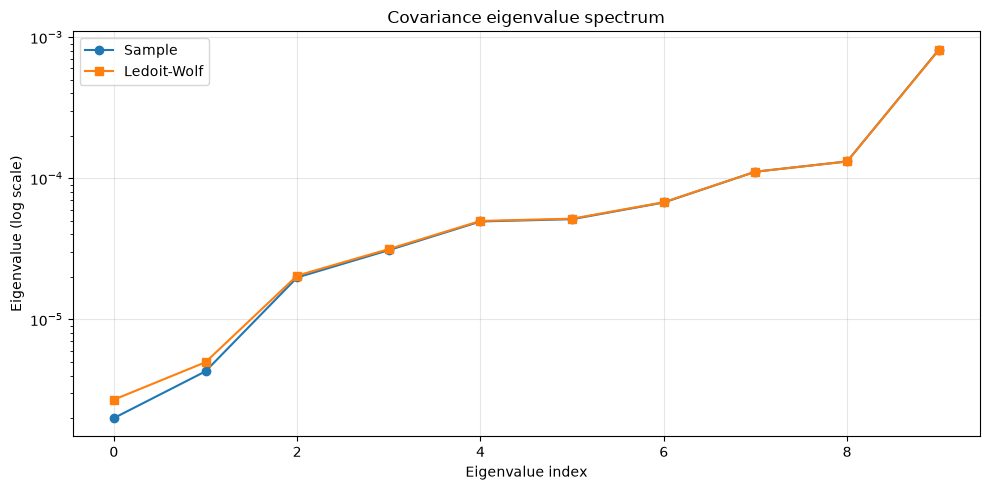

In [13]:
sample_cov = estimate_cov(returns, "sample") / 252
ledoit_cov = estimate_cov(returns, "ledoit") / 252

eig_sample = np.linalg.eigvalsh(sample_cov)
eig_ledoit = np.linalg.eigvalsh(ledoit_cov)

plt.figure(figsize=(10, 5))
plt.plot(eig_sample, "o-", label="Sample")
plt.plot(eig_ledoit, "s-", label="Ledoit-Wolf")
plt.yscale("log")
plt.xlabel("Eigenvalue index")
plt.ylabel("Eigenvalue (log scale)")
plt.title("Covariance eigenvalue spectrum")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/eigenvalues.png", dpi=150)
plt.show()

## 2. Weight stability across rebalances

If sample covariance is noisy, optimal weights will swing wildly from one
rebalance to the next. Shrinkage should reduce that oscillation.

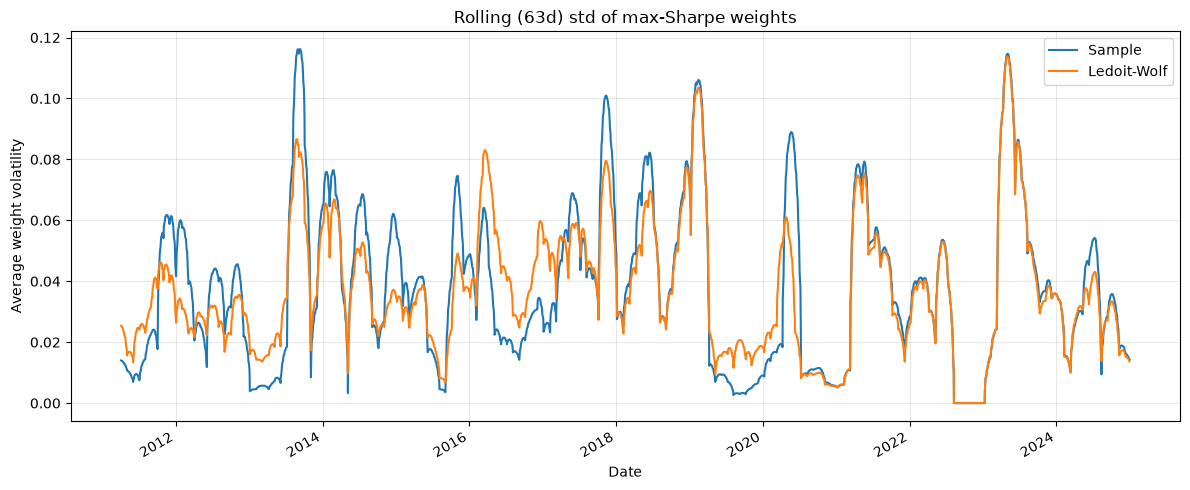

In [11]:
from src.backtest import backtest

_, w_sample, _ = backtest(returns, method="max_sharpe", estimator="sample")
_, w_ledoit, _ = backtest(returns, method="max_sharpe", estimator="ledoit")

roll_std_sample = w_sample.rolling(63).std().mean(axis=1)
roll_std_ledoit = w_ledoit.rolling(63).std().mean(axis=1)

plt.figure(figsize=(12, 5))
roll_std_sample.plot(label="Sample")
roll_std_ledoit.plot(label="Ledoit-Wolf")
plt.title("Rolling (63d) std of max-Sharpe weights")
plt.ylabel("Average weight volatility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("results/weight_stability.png", dpi=150)
plt.show()

## 3. Return correlations

The structure of the covariance matrix comes from the correlation structure
of the assets. Equities (SPY, QQQ, IWM, EFA, EEM) are highly correlated;
bonds (AGG, TLT) and gold (GLD) provide diversification.

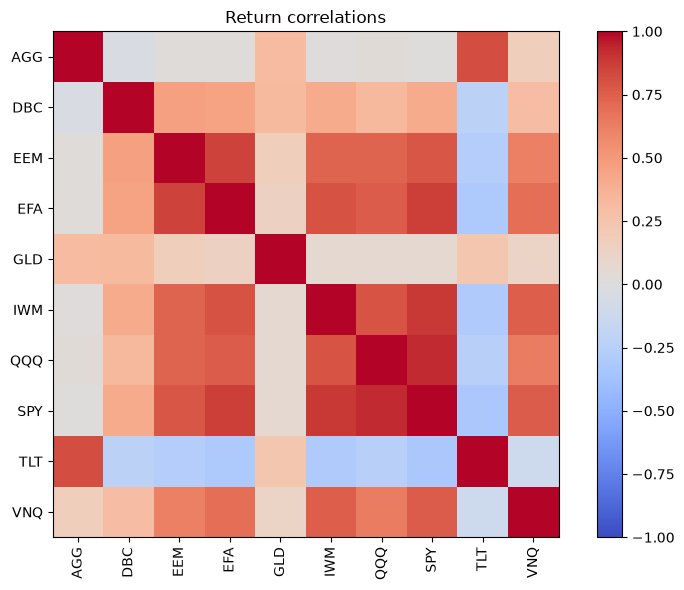

In [12]:
plt.figure(figsize=(8, 6))
plt.imshow(returns.corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(returns.columns)), returns.columns, rotation=90)
plt.yticks(range(len(returns.columns)), returns.columns)
plt.title("Return correlations")
plt.tight_layout()
plt.savefig("results/correlation.png", dpi=150)
plt.show()

## What this shows

- **Eigenvalue spectrum:** Sample covariance has a long right tail and a
  dense small-eigenvalue cluster. Ledoit-Wolf flattens the spectrum by
  pulling extreme eigenvalues toward the mean, which is exactly what makes
  the inverse (and therefore the optimal weights) more stable.

- **Weight stability:** Rolling weight volatility is lower under shrinkage
  for max-Sharpe. This explains the modest Sharpe improvement without
  turnover increasing — the weights move less per rebalance.

- **Correlations:** Equity block is highly correlated; bonds and gold
  break the structure. Min-variance exploits this automatically.

**Why the improvement is modest here:** with N=10 assets and T=252 per
training window, the sample covariance is already well-conditioned (T >> N).
Shrinkage matters more when N approaches or exceeds T — e.g., a 500-stock
universe with a 252-day window.